# Part 3 : Visualising acceptability degree spaces for gradual semantics

We recall that a weighted gradual semantics $\Sigma$ associates to each weighted argumentation framework $F=(A,R,w)$, a function $\Sigma(F): A \to [0,1]$. We define the weighted h-categorizer semantics $\Sigma_{HC}$ as follows. For any $F=(A,R,w)$ and $a \in A$, we have:

$$\Sigma_{HC}(F)(a) = \lim_{k \to \infty} HC_k(a)$$

for the sequence of functions $HC_k: A \to [0,1]$ defined recursively by

$$
HC_{k+1}(a) = \frac{w(a)}{1+ \sum_{b \in Att(a)} HC_k(b)}$$

###Question 1 (2 pts) : Implement the weighted h-categorizer semantics, using a parameter $\epsilon > 0$ to control the convergence.

In [ ]:
import numpy as np

def compute_h_categorizer_nd(w_vectors, attackers, epsilon=1e-4, max_iter=1000):
    """
    Version pour N arguments et un graphe dynamique.

    :param w_vectors: Tableau NumPy de forme (100000, nb_arguments)
    :param attackers: Dictionnaire des attaques
    """
    x = w_vectors.copy()
    nb_arguments = w_vectors.shape[1] # Sera 5, 10 ou 20

    for _ in range(max_iter):
        x_new = np.zeros_like(x)

        # Pour chaque argument, on applique la formule sur les 100 000 lignes d'un coup
        for a in range(nb_arguments):
            atts = attackers.get(a, [])

            if not atts:
                # Si pas d'attaquants, la somme est 0
                sum_attackers = 0.0
            else:
                # On additionne les colonnes correspondantes aux attaquants
                # np.sum sur l'axe 1 fait la somme horizontale pour chaque vecteur
                sum_attackers = np.sum(x[:, atts], axis=1)
            # Application de la formule vectorisée
            x_new[:, a] = w_vectors[:, a] / (1.0 + sum_attackers)

        # Vérification de la convergence globale
        if np.max(np.abs(x_new - x)) < epsilon:
            break

        x = x_new

    return x

# --- EXEMPLE D'UTILISATION ---

NB_ARGUMENTS = 3

# 2. Création de la matrice de poids (W)
# Format : 1 ligne (notre seul échantillon) et 3 colonnes (les poids de a, b, c)
W = np.array([[0.8, 0.5, 1.0]])

# 3. création du dictionnaire d'attaques (att2 : a et b s'attaquent mutuellement)

att2_nd = {
    0: [1],  # L'argument 0 ('a') est attaqué par 1 ('b')
    1: [0],  # L'argument 1 ('b') est attaqué par 0 ('a')
    2: []    # L'argument 2 ('c') n'a pas d'attaquant
}

# 4. Appel de la fonction vectorisée

X_finaux = compute_h_categorizer_nd(W, att2_nd, epsilon=0.001)

# 5. Affichage du résultat
print("\nScores finaux :")

print(f"Argument a (0) : {X_finaux[0, 0]:.4f}")
print(f"Argument b (1) : {X_finaux[0, 1]:.4f}")
print(f"Argument c (2) : {X_finaux[0, 2]:.4f}")






Scores finaux :
Argument a (0) : 0.6098
Argument b (1) : 0.3102
Argument c (2) : 1.0000


###Question 2 (5 pts) Note that by fixing an arbitrary order on $A$, we can convert $w$ into a vector in $[0,1]^A$. For example, if $w(a)=0.2$ and $w(b)=0.5$, we obtain the vector $[0.2,0.5]$. Thus, for a given argumentation framework $(A, R)$ without weights, the semantics $\Sigma_{HC}$ converts $w$ into a vector $x \in [0,1]^A$.

  

Implement a program that:

1. Take as input an argumentation framework $(A,R)$
2. Sample 100,000 random vectors $w_i \in [0,1]^A$ and compute the corresponding vectors $x_i \in [0,1]^A$.
3. Construct and display the convex hull of the points $x_i$. This hull is an approximation of the space of acceptability degree of $(A,R)$ for the h-categorizer semantics.
4. Apply a heat-map on the convex hull to display areas with large/low density. Is this heat-map resilient to re-sampling? Vary the argumentation frameworks and the number of arguments. Write down your analysis.

### a. Création du cadre d'argumentation

On pose dans un premier temps un cadre à 2 arguments (a et b), où b attaque a et où personne n'attaque b.

In [ ]:
import numpy as np

def compute_h_categorizer_2d(w_vectors, R, epsilon=1e-4, max_iter=1000):
    """
    Calcule les vecteurs x pour un grand nombre de vecteurs w simultanément.
    Cas spécifique pour 2 arguments A = {0, 1} pour optimiser les 100 000 calculs.
    """
    x = w_vectors.copy()

    for _ in range(max_iter):
        x_new = np.zeros_like(x)
        # Supposons le graphe R : b attaque a (ex: a <- b)
        # Formule : HC(a) = w(a) / (1 + sum(HC(b)))
        x_new[:, 0] = w_vectors[:, 0] / (1.0 + x[:, 1]) # b attaque a
        x_new[:, 1] = w_vectors[:, 1] / 1.0             # personne n'attaque b

        if np.max(np.abs(x_new - x)) < epsilon:
            break
        x = x_new

    return x

### b. Échantillonnage de 100 000 vecteurs aléatoires $w_i$ dans $[0, 1]^2$


---



In [ ]:
# Échantillonnage de 100 000 vecteurs aléatoires w_i dans [0, 1]^2
N_SAMPLES = 100000
W = np.random.rand(N_SAMPLES, 2)

# Calcul des vecteurs x_i correspondants
X = compute_h_categorizer_2d(W, R=None)

### c. Construction de l'enveloppe convexe




Text(0, 0.5, 'Score Argument 1')

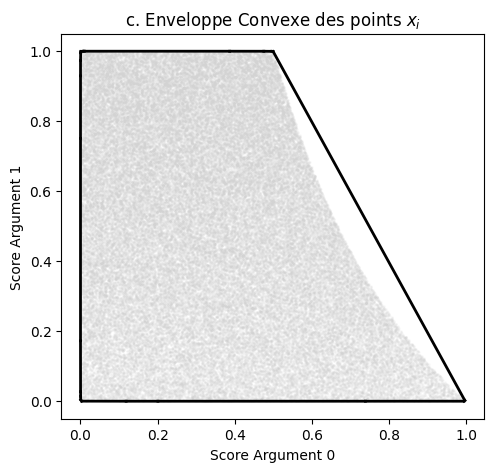

In [ ]:
from scipy.spatial import ConvexHull
import matplotlib.pyplot as plt


# Construction de l'enveloppe convexe
hull = ConvexHull(X)

# Création de la figure
plt.figure(figsize=(12, 5))

# --- Affichage de l'enveloppe convexe ---
plt.subplot(1, 2, 1)
plt.plot(X[:, 0], X[:, 1], 'o', markersize=1, color='lightgray', alpha=0.1)
for simplex in hull.simplices:
    plt.plot(X[simplex, 0], X[simplex, 1], 'k-', lw=2)
plt.title("c. Enveloppe Convexe des points $x_i$")
plt.xlabel("Score Argument 0")
plt.ylabel("Score Argument 1")


### d. Affichage de la heat-map


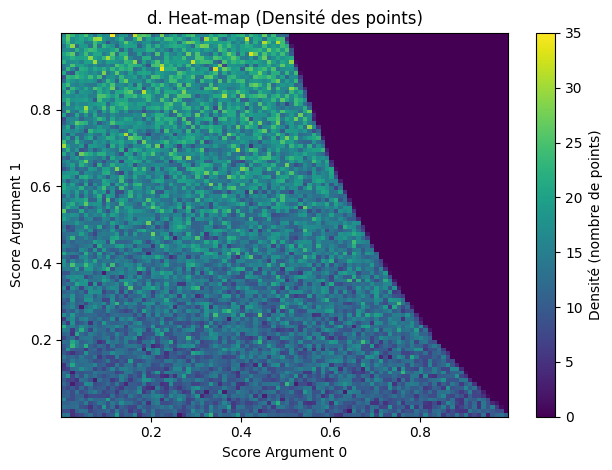

In [ ]:
# Affichage de la carte de chaleur (Heat-map)
plt.subplot(1, 1, 1)
# Utilisation de hist2d pour montrer la densité
plt.hist2d(X[:, 0], X[:, 1], bins=100, cmap='viridis')
plt.colorbar(label='Densité (nombre de points)')
plt.title("d. Heat-map (Densité des points)")
plt.xlabel("Score Argument 0")
plt.ylabel("Score Argument 1")

plt.tight_layout()
plt.show()

###Etude comparative

Nous allons étudier comment évolue la heat-map lorsque le cadre d'argumentation et le nombre d'arguments varient.

On pose 3 cadres d'argumentation, constitués respectivement de 5,10,20 arguments.

Pour chaque cadre, on va effectuer 2 sous cadres : un premier avec peu de relations et un second avec beaucoup de relations. On va ainsi mettre en évidence l'impact du nombre d'arguments et du nombre de relations sur la heatmap.

On repart donc la fonction h-categorizer appliquée à la dimension n.

In [ ]:
import numpy as np

def compute_h_categorizer_nd(w_vectors, attackers, epsilon=1e-4, max_iter=1000):
    """
    Version vectorisée (très rapide) pour N arguments

    :param w_vectors: Tableau NumPy de forme (100000, nb_arguments)
    :param attackers: Dictionnaire des attaques généré précédemment
    """
    x = w_vectors.copy()
    nb_arguments = w_vectors.shape[1] # Sera 5, 10 ou 20

    for _ in range(max_iter):
        x_new = np.zeros_like(x)

        # Pour chaque argument, on applique la formule sur les 100 000 lignes d'un coup
        for a in range(nb_arguments):
            atts = attackers.get(a, [])

            if not atts:
                # Si pas d'attaquants, la somme est 0
                sum_attackers = 0.0
            else:
                # On additionne les colonnes correspondantes aux attaquants
                # np.sum sur l'axe 1 fait la somme horizontale pour chaque vecteur
                sum_attackers = np.sum(x[:, atts], axis=1)
            # Application de la formule vectorisée
            x_new[:, a] = w_vectors[:, a] / (1.0 + sum_attackers)

        # Vérification de la convergence globale
        if np.max(np.abs(x_new - x)) < epsilon:
            break

        x = x_new

    return x

Puisque le nombre d'arguments augmente considérablement, on crée également une fonction pou créer le dictionnaire automatiquement.

In [ ]:
import random

# 1. Fonction pour créer le dictionnaire automatiquement
def creer_dictionnaire_attaques(nb_arguments, probabilite):
    attackers = {}
    for cible in range(nb_arguments):
        attaquants_de_cette_cible = []
        for attaquant in range(nb_arguments):
            # On vérifie qu'un argument ne s'attaque pas lui-même
            if attaquant != cible:
                # La probabilité décide si l'attaque existe (ex: 0.2 = 20% de chances)
                if random.random() < probabilite:
                    attaquants_de_cette_cible.append(attaquant)

        attackers[cible] = attaquants_de_cette_cible

    return attackers


In [ ]:
NB_ARGUMENTS = 5
PROBA_DENSITE = 0.2 # 0.2 pour "peu de relations", 0.8 pour "beaucoup"

# On crée le dictionnaire
dictionnaire_att = creer_dictionnaire_attaques(NB_ARGUMENTS, PROBA_DENSITE)
print("Dictionnaire généré :", dictionnaire_att)

# On génère les 100 000 vecteurs de poids (w) entre 0 et 1
N_SAMPLES = 100000
W = np.random.rand(N_SAMPLES, NB_ARGUMENTS)

# On lance le calcul final (avec la fonction compute_h_categorizer_nd vue précédemment)
X_finaux = compute_h_categorizer_nd(W, dictionnaire_att)

Dictionnaire généré : {0: [2], 1: [0], 2: [], 3: [1], 4: []}


Nous allons ensuite écrire une fonction pour réaliser en une seule fois l'étude comparative.


Calcul en cours : 5 arguments, densité 0.2...
{0: [], 1: [], 2: [0], 3: [0], 4: []}

Calcul en cours : 5 arguments, densité 0.8...
{0: [1, 2, 3, 4], 1: [0, 2, 3, 4], 2: [0, 1, 3], 3: [0, 1, 2, 4], 4: [0, 1, 2, 3]}

Calcul en cours : 10 arguments, densité 0.2...
{0: [5, 6], 1: [7, 8], 2: [6], 3: [1], 4: [0, 7], 5: [0, 3, 4], 6: [5, 7, 8], 7: [2, 5], 8: [5], 9: []}

Calcul en cours : 10 arguments, densité 0.8...
{0: [2, 4, 5, 6, 8, 9], 1: [0, 2, 3, 5, 6, 8, 9], 2: [0, 1, 3, 4, 5, 7, 9], 3: [0, 1, 2, 4, 5, 6, 7, 8, 9], 4: [0, 1, 2, 3, 5, 7, 8, 9], 5: [0, 1, 2, 3, 4, 6, 7, 8, 9], 6: [0, 1, 2, 3, 7, 8, 9], 7: [1, 2, 3, 4, 5, 6, 8, 9], 8: [0, 1, 2, 3, 4, 6, 7], 9: [0, 1, 2, 3, 4, 5, 7, 8]}

Calcul en cours : 20 arguments, densité 0.2...
{0: [2, 5, 12, 18], 1: [13, 16], 2: [0, 4, 7, 13, 14], 3: [1, 5, 15], 4: [11, 14], 5: [11, 12, 16, 18, 19], 6: [1, 4, 12], 7: [1, 2, 14, 18], 8: [1, 9, 15], 9: [0, 8, 11, 19], 10: [1, 2, 6, 7, 13, 15, 17], 11: [19], 12: [3, 14, 19], 13: [11, 16, 17], 14: [1,

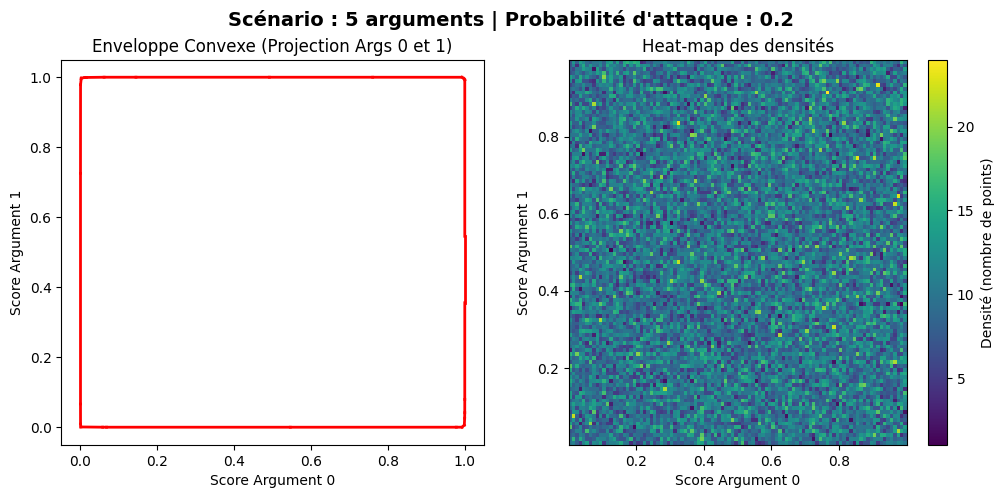

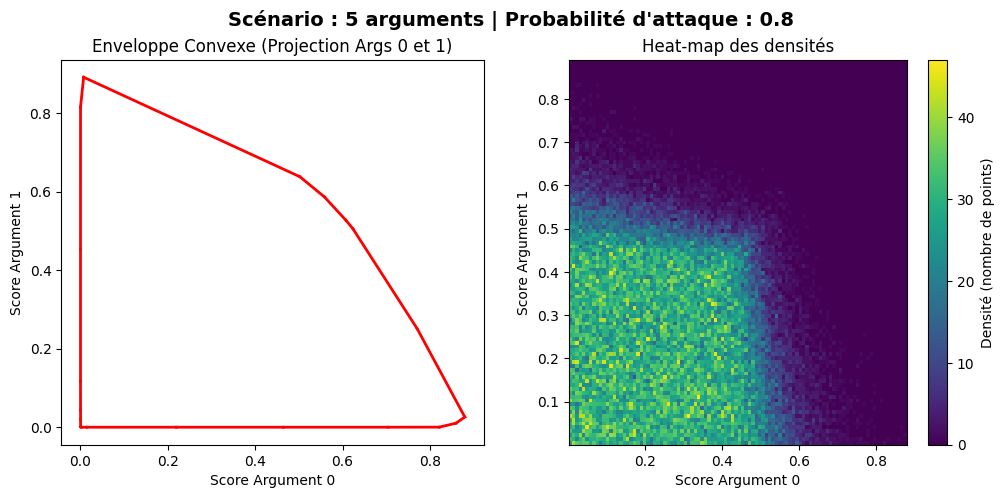

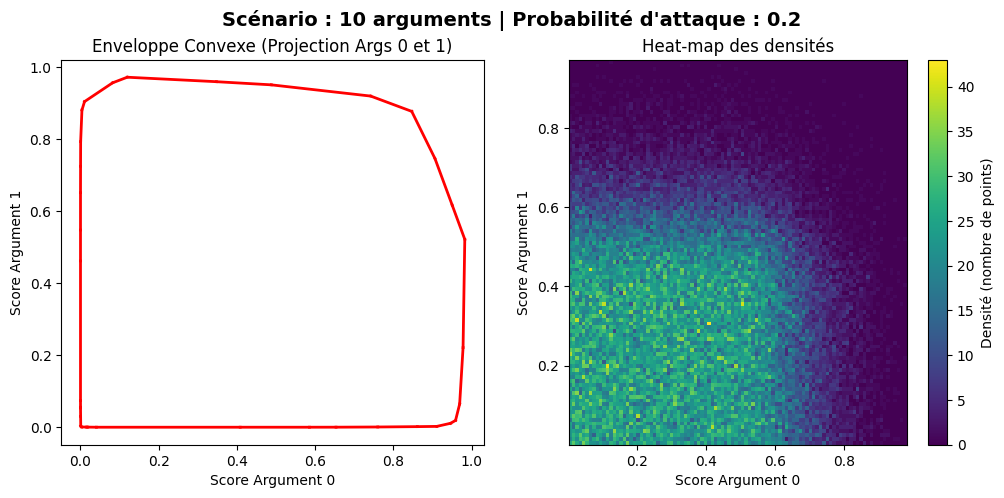

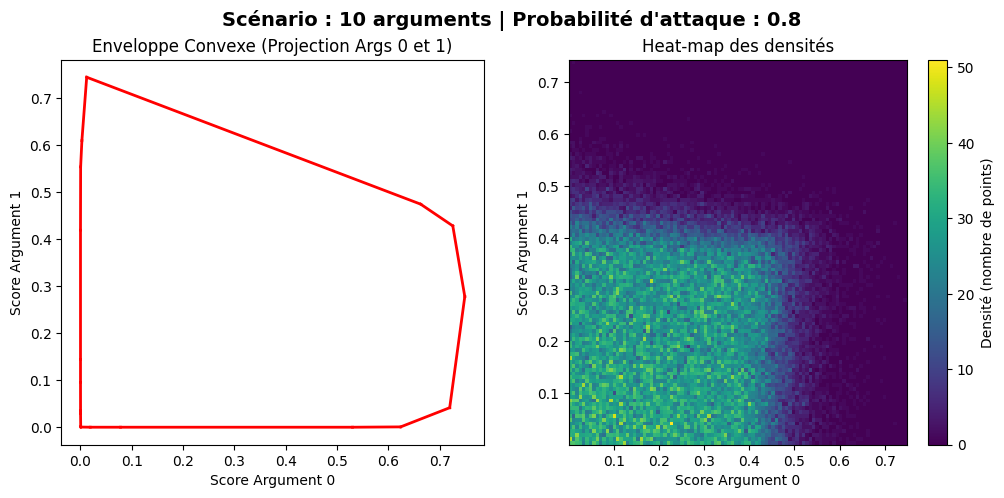

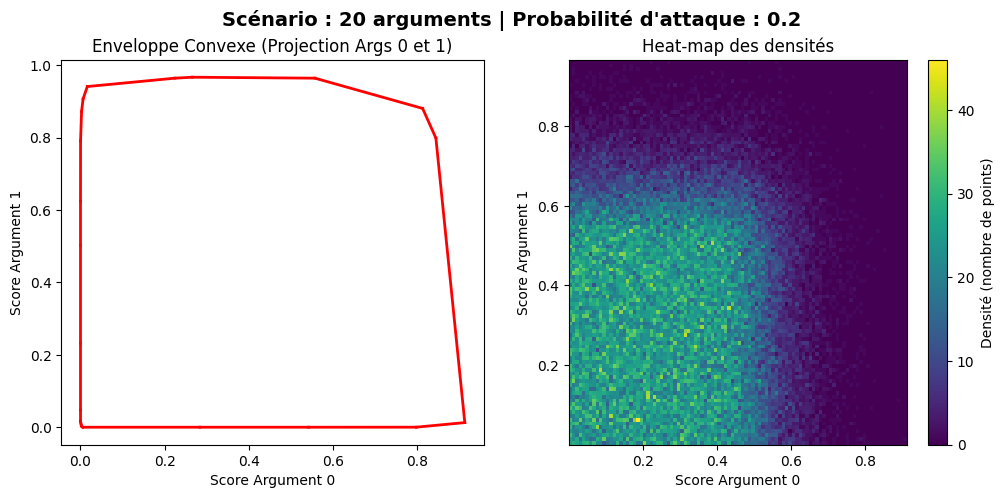

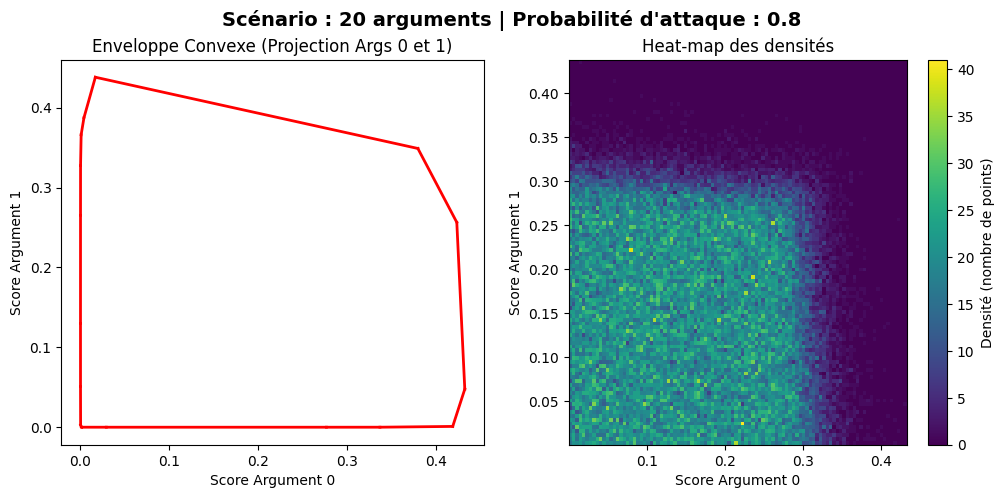

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA # Correction de l'import
from scipy.spatial import ConvexHull

N_SAMPLES = 100000
epsilon = 1e-4
max_iter = 1000

# Fonction pour effectuer l'étude comparative

for NB_ARGUMENTS in [5, 10, 20]:
    for PROBA in [0.2, 0.8]:
        print(f"\nCalcul en cours : {NB_ARGUMENTS} arguments, densité {PROBA}...")

        # 1. Génération et Calculs
        W = np.random.rand(N_SAMPLES, NB_ARGUMENTS)
        dictionnaire_att = creer_dictionnaire_attaques(NB_ARGUMENTS, PROBA)
        print(dictionnaire_att)
        # Ce calcul peut prendre quelques secondes, c'est normal
        X_finaux = compute_h_categorizer_nd(W, dictionnaire_att,epsilon,max_iter)

        X_ref = X_finaux[:,[0,1]]

        # 3. Calcul de l'enveloppe
        hull = ConvexHull(X_ref)

        # 4. Affichage
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
        fig.suptitle(f"Scénario : {NB_ARGUMENTS} arguments | Probabilité d'attaque : {PROBA}", fontsize=14, fontweight='bold')

        # --- GAUCHE : Enveloppe Convexe ---
        for simplex in hull.simplices:
            ax1.plot(X_ref[simplex, 0], X_ref[simplex, 1], 'r-', lw=2)

        # CORRECTION DES TITRES ICI :
        ax1.set_title("Enveloppe Convexe (Projection Args 0 et 1)")
        ax1.set_xlabel("Score Argument 0")
        ax1.set_ylabel("Score Argument 1")

        # --- DROITE : Heat-map ---
        h = ax2.hist2d(X_ref[:, 0], X_ref[:, 1], bins=100, cmap='viridis')
        fig.colorbar(h[3], ax=ax2, label='Densité (nombre de points)')

        # AJOUT DES TITRES POUR LA HEATMAP :
        ax2.set_title("Heat-map des densités")
        ax2.set_xlabel("Score Argument 0")
        ax2.set_ylabel("Score Argument 1")

Une des prinicpales limites concerne la création aléatoire d'attaquants qui peut avoir un impact sur la forme du graphe et donc le dégré d'acceptabilité des arguments. Pour contourner ce problème, nous allons créer 3 structures fixes (étoile, cyclique, biparti) et faire varier le nombre d'arguments.


Calcul en cours : 5 arguments, att_etoile


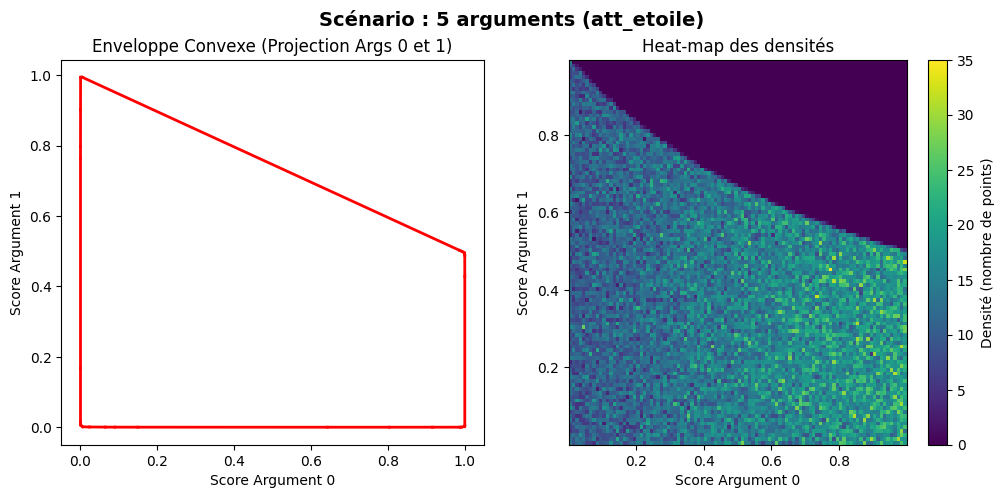


Calcul en cours : 5 arguments, att_cycle


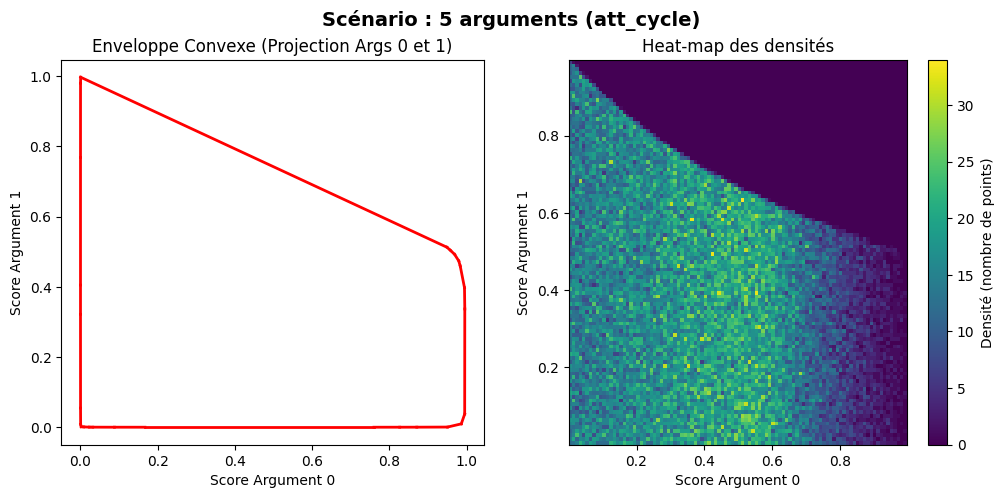


Calcul en cours : 5 arguments, att_biparti


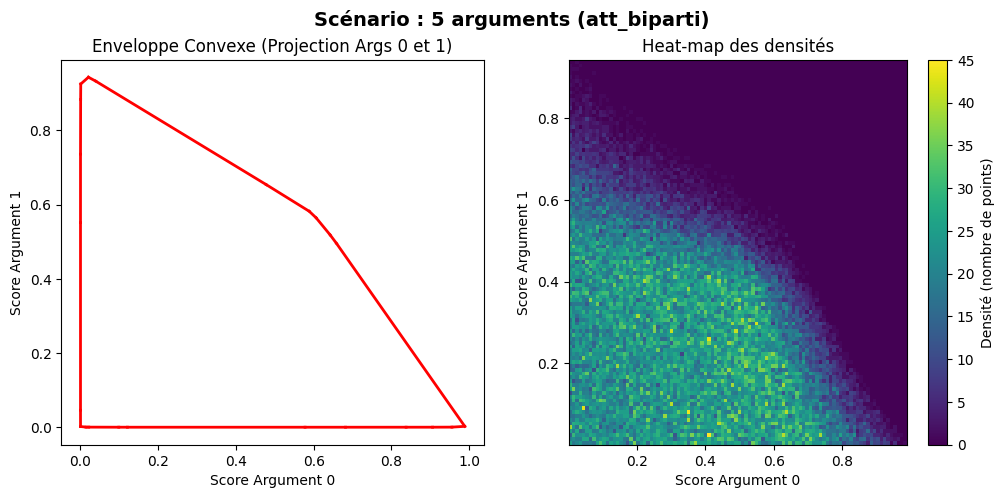


Calcul en cours : 10 arguments, att_etoile


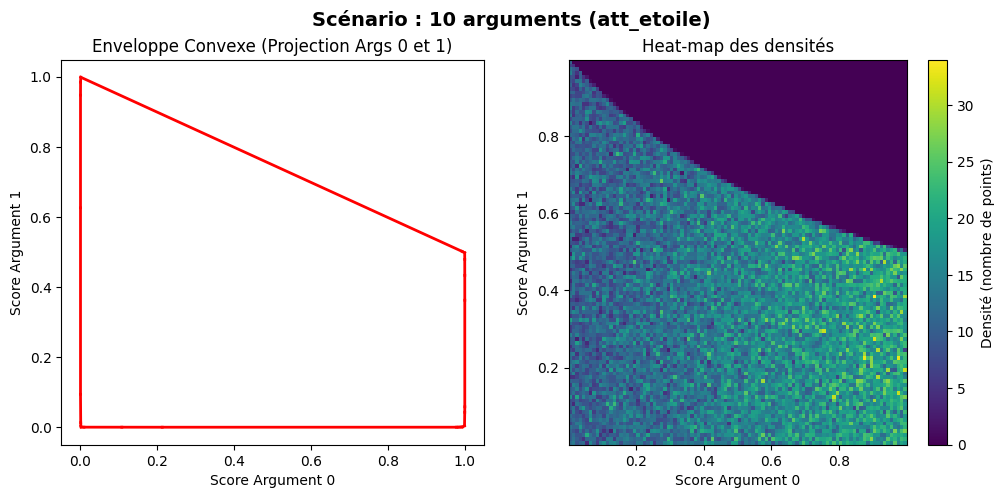


Calcul en cours : 10 arguments, att_cycle


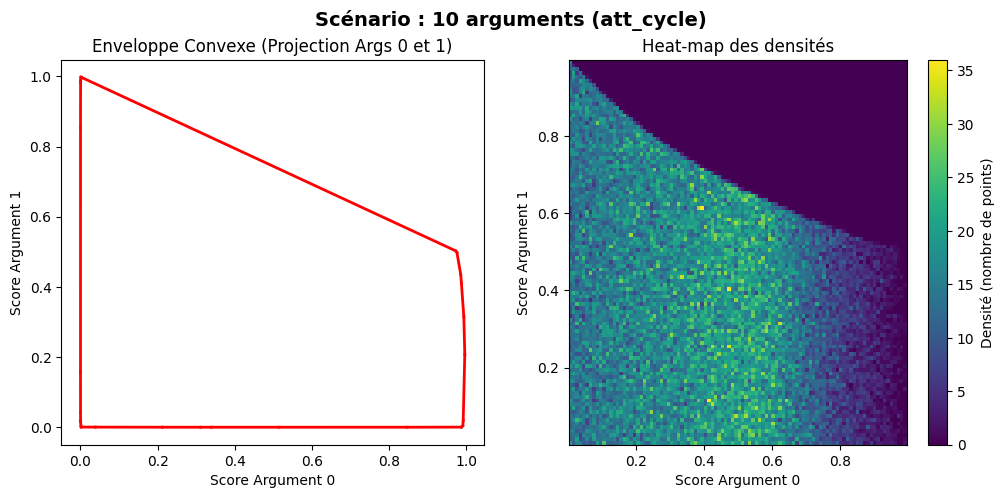


Calcul en cours : 10 arguments, att_biparti


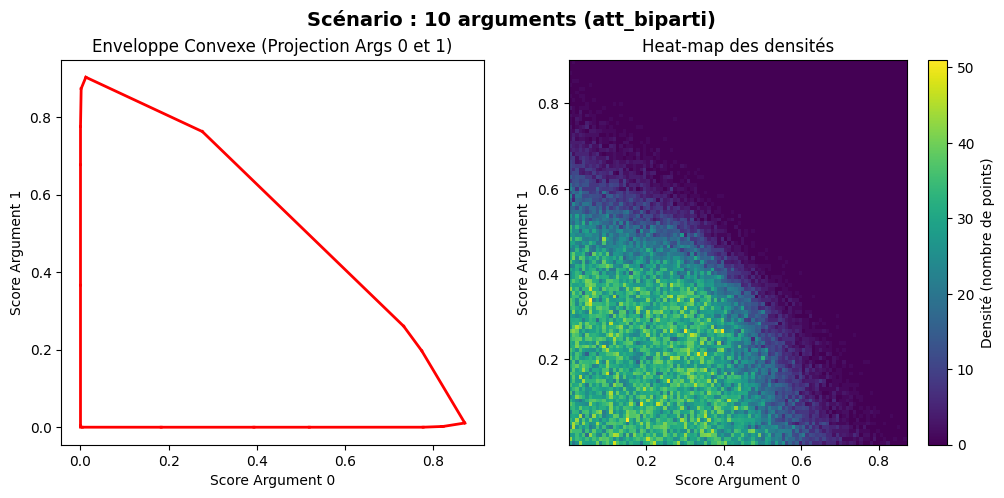


Calcul en cours : 20 arguments, att_etoile


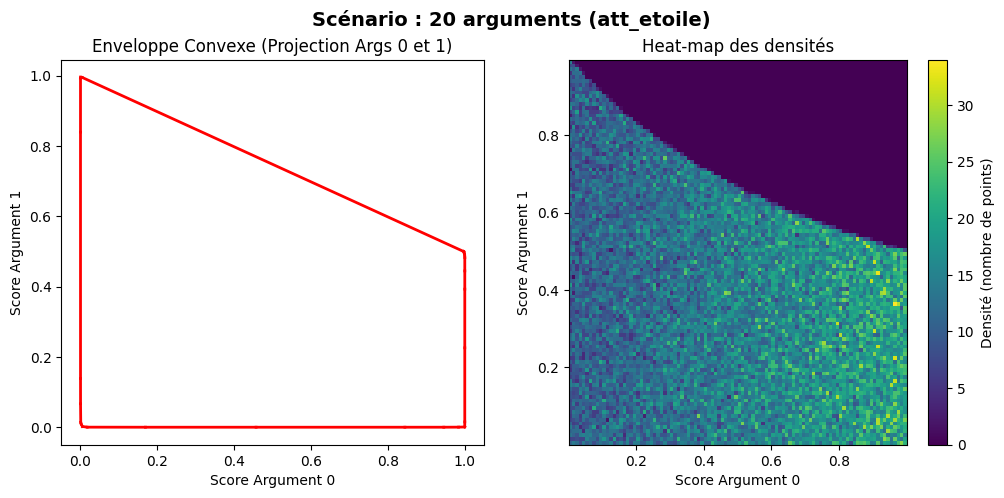


Calcul en cours : 20 arguments, att_cycle


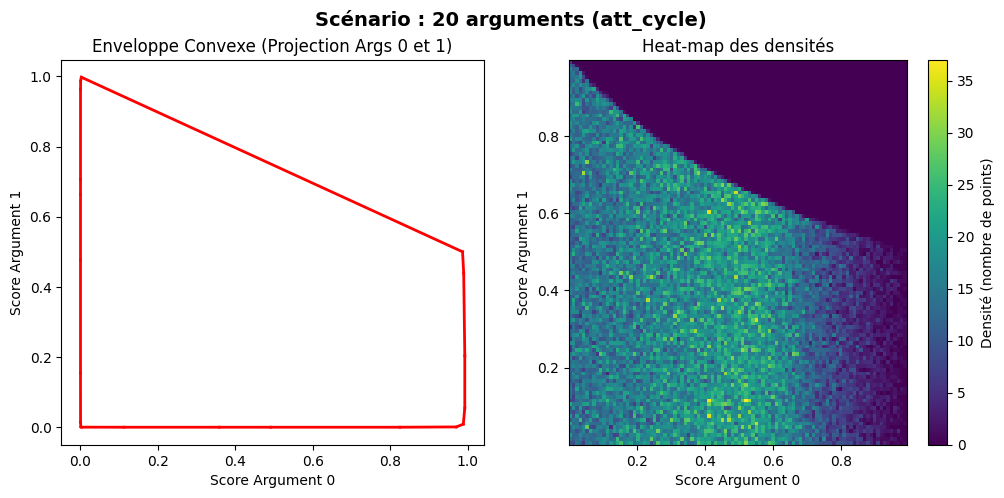


Calcul en cours : 20 arguments, att_biparti


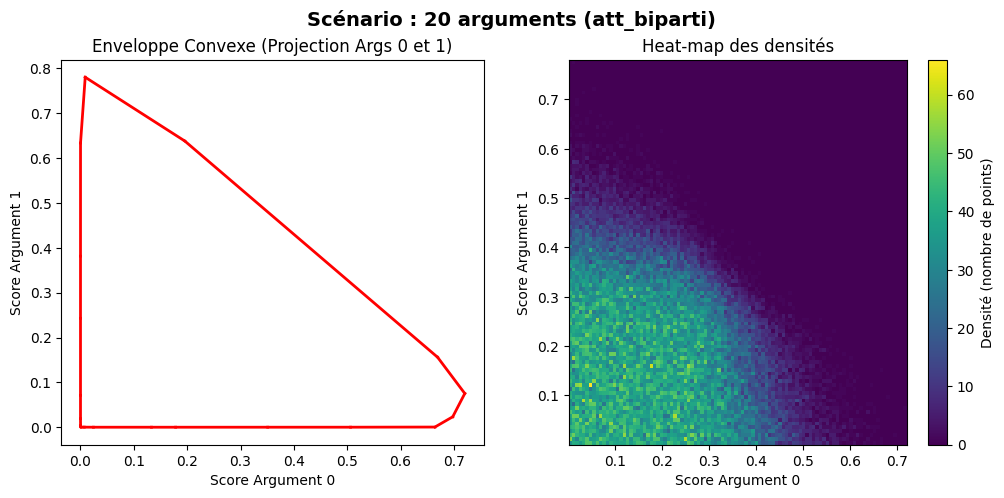

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull

N_SAMPLES = 100000

for NB_ARGUMENTS in [5, 10, 20]:

  att_etoile = {i: ([0] if i != 0 else []) for i in range(NB_ARGUMENTS)}
  att_cycle = {i: [(i - 1) % NB_ARGUMENTS] for i in range(NB_ARGUMENTS)}
  att_biparti = {i: [j for j in range(NB_ARGUMENTS) if j % 2 != i % 2] for i in range(NB_ARGUMENTS)}

  # Regroupement dans un dictionnaire pour l'accès dynamique
  att_structures = {
      "att_etoile": att_etoile,
      "att_cycle": att_cycle,
      "att_biparti": att_biparti
  }

  for att_type in ["att_etoile", "att_cycle", "att_biparti"]:
        print(f"\nCalcul en cours : {NB_ARGUMENTS} arguments, {att_type}")

        # 1. Génération et Calculs
        W = np.random.rand(N_SAMPLES, NB_ARGUMENTS)

        # On récupère le vrai dictionnaire d'attaques associé au nom
        dictionnaire_selectionne = att_structures[att_type]

        # Ce calcul peut prendre quelques secondes, c'est normal
        X_finaux = compute_h_categorizer_nd(W, dictionnaire_selectionne)

        X_ref = X_finaux[:,[0,1]]

        # 3. Calcul de l'enveloppe
        hull = ConvexHull(X_ref)

        # 4. Affichage (Correction de la grille de sous-graphiques : 1 ligne, 2 colonnes)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
        fig.suptitle(f"Scénario : {NB_ARGUMENTS} arguments ({att_type})", fontsize=14, fontweight='bold')

        # --- GAUCHE : Enveloppe Convexe ---
        for simplex in hull.simplices:
            ax1.plot(X_ref[simplex, 0], X_ref[simplex, 1], 'r-', lw=2)

        # CORRECTION DES TITRES ICI :
        ax1.set_title("Enveloppe Convexe (Projection Args 0 et 1)")
        ax1.set_xlabel("Score Argument 0")
        ax1.set_ylabel("Score Argument 1")

        # --- DROITE : Heat-map ---
        h = ax2.hist2d(X_ref[:, 0], X_ref[:, 1], bins=100, cmap='viridis')
        fig.colorbar(h[3], ax=ax2, label='Densité (nombre de points)')

        # AJOUT DES TITRES POUR LA HEATMAP :
        ax2.set_title("Heat-map des densités")
        ax2.set_xlabel("Score Argument 0")
        ax2.set_ylabel("Score Argument 1")

        plt.savefig("grille_complete.pdf", format="pdf", bbox_inches="tight")
        plt.show()

###Résistance au réechantillonnage



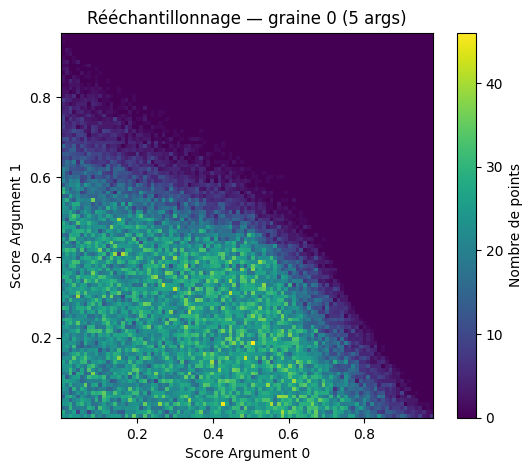

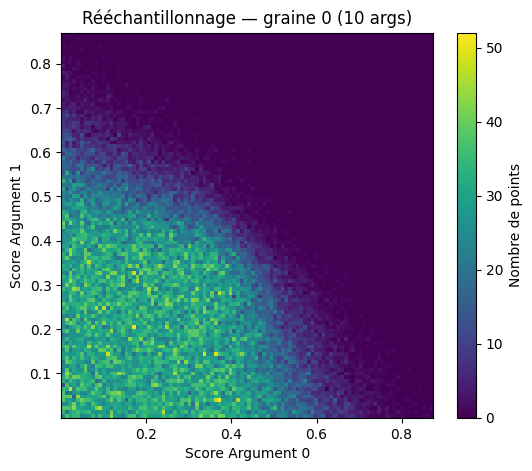

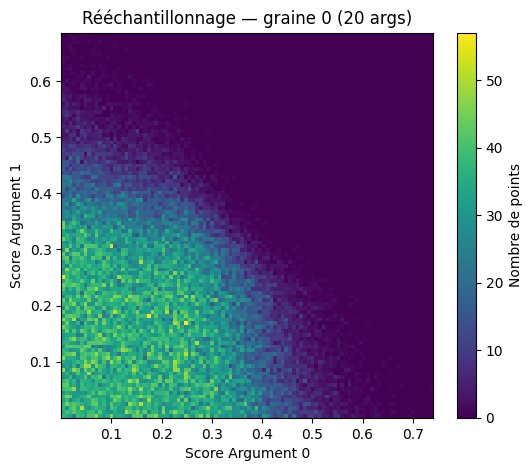

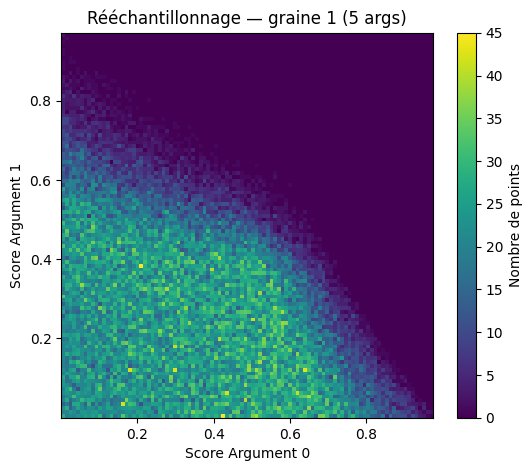

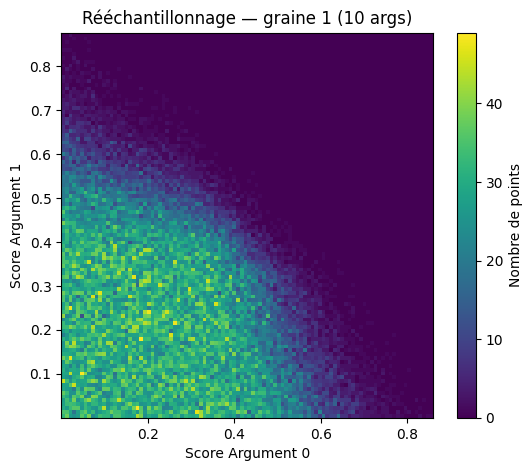

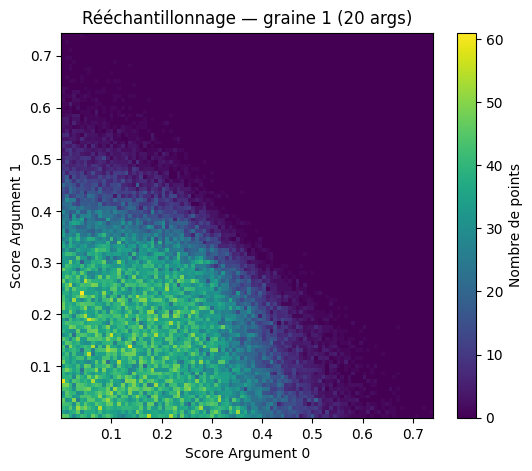

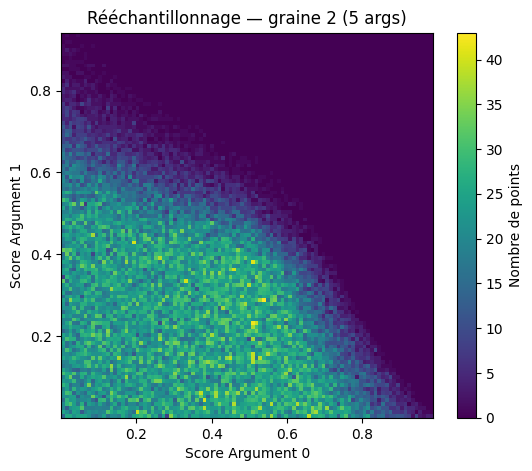

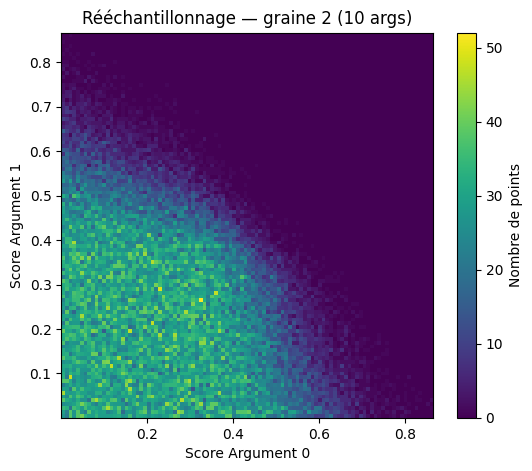

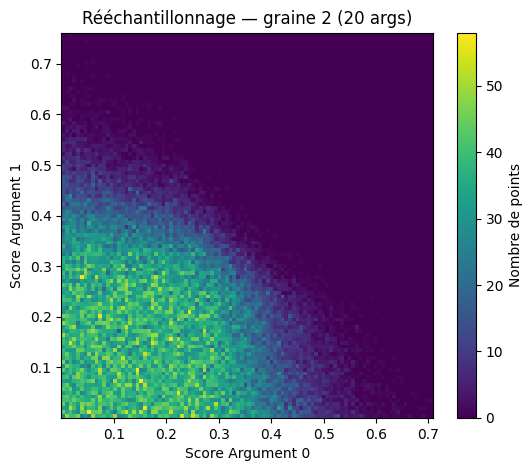

In [ ]:
for seed in [0, 1, 2]:
    np.random.seed(seed)

    N_SAMPLES = 100000

    for NB_ARGUMENTS in [5, 10, 20]:
      # On recrée les structures d'attaques adaptées à la taille actuelle de NB_ARGUMENTS
      att_etoile = {i: ([0] if i != 0 else []) for i in range(NB_ARGUMENTS)}
      att_cycle = {i: [(i - 1) % NB_ARGUMENTS] for i in range(NB_ARGUMENTS)}
      att_biparti = {i: [j for j in range(NB_ARGUMENTS) if j % 2 != i % 2] for i in range(NB_ARGUMENTS)}

      # Par exemple, on choisit d'analyser la structure bipartie pour ce test (on peut changer avec att_etoile et att_cycle)
      dictionnaire_selectionne = att_biparti

      W = np.random.rand(N_SAMPLES, NB_ARGUMENTS)
      X_finaux = compute_h_categorizer_nd(
          W, dictionnaire_selectionne
      )

      X_ref = X_finaux[:, [0, 1]]

      plt.figure(figsize=(6, 5))
      plt.hist2d(
          X_ref[:, 0], X_ref[:, 1],
          bins=100, cmap="viridis"
      )
      plt.colorbar(label="Nombre de points")
      plt.title(f"Rééchantillonnage — graine {seed} ({NB_ARGUMENTS} args)")
      plt.xlabel("Score Argument 0")
      plt.ylabel("Score Argument 1")
      plt.show()